In [101]:
!pip install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# fetch dataset
airfoil_self_noise = fetch_ucirepo(id=291)

# data (as pandas dataframes)
X = airfoil_self_noise.data.features
Y = airfoil_self_noise.data.targets

S = pd.concat([X,Y], axis=1)

# metadata
print(airfoil_self_noise.metadata)

# variable information
print(airfoil_self_noise.variables)

{'uci_id': 291, 'name': 'Airfoil Self-Noise', 'repository_url': 'https://archive.ics.uci.edu/dataset/291/airfoil+self+noise', 'data_url': 'https://archive.ics.uci.edu/static/public/291/data.csv', 'abstract': 'NASA data set, obtained from a series of aerodynamic and acoustic tests of two and three-dimensional airfoil blade sections conducted in an anechoic wind tunnel.', 'area': 'Physics and Chemistry', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1503, 'num_features': 5, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['scaled-sound-pressure'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C5VW2C', 'creators': ['Thomas Brooks', 'D. Pope', 'Michael Marcolini'], 'intro_paper': None, 'additional_info': {'summary': 'The NASA data set comprises different size NACA 0012 airfoils at various wind tunnel speeds and angles of

In [102]:
#Cek Variabel
airfoil_self_noise.variables

,name,role,type,demographic,description,units,missing_values
0,frequency,Feature,Integer,None,None,Hz,no
1,attack-angle,Feature,Binary,None,None,deg,no
2,chord-length,Feature,Continuous,None,None,m,no
3,free-stream-velocity,Feature,Continuous,None,None,m/s,no
4,suction-side-displacement-thickness,Feature,Continuous,None,None,m,no
5,scaled-sound-pressure,Target,Continuous,None,None,dB,no


**PENJELASAN TERKAIT VARIABEL**

*   Frequency menunjukkan pada nada/ketinggian suara apa kebisingan itu terjadi
*   Attack-angle menunjukkan sudut antara garis chord sayap dan arah aliran udara yang datang, diukur dalam derajat
*   Chord-length menunjukkan Panjang garis lurus dari tepi depan (leading edge) ke tepi belakang (trailing edge) sayap, dalam meter
*   Free-Stream-Velocity menunjukkan kecepatan udara yang mengalir menuju sayap, dalam meter per detik (m/s)
*   Suction-Side-Displacement-Thickness untuk ukuran ketebalan lapisan batas (boundary layer) di sisi hisap (suction side) sayap, dalam meter . Ini adalah parameter yang sangat teknis dan menunjukkan seberapa “tebal” lapisan udara yang melambat di dekat permukaan sayap
*   Scaled-Sound-Pressure menunjukkan tingkat tekanan suara yang diskalakan, diukur dalam desibel (dB) . Ini adalah ukuran seberapa keras suara yang dihasilkan.


In [103]:
#Cek Shape
print(f"shape dari features: {X.shape}")
print(f"shape dari targets: {Y.shape}")

shape dari features: (1503, 5)
shape dari targets: (1503, 1)


Dari atas terlihat bahwa data memiliki 1503 Observasi dan 5 Variabel fitur dan 1 variabel targets

In [104]:
# Menampilkan ringkasan statistik dari semuanya
print(f"Statistika Deskriptif terkait File Airsoft ")
S.describe()

Statistika Deskriptif terkait File Airsoft 


,frequency,attack-angle,chord-length,free-stream-velocity,suction-side-displacement-thickness,scaled-sound-pressure
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


Lebih lanjut kita lakukan Pre-Processing Terlebih dahulu. Terutama pada


*   Duplikat
*   Anomali
*   Missing Values
*   Outlier (ditangani lebih lanjut apabila diperlukan)

In [105]:
#Cek Duplikat
print(f"Terdapat duplikat sebanyak", S.duplicated().sum())
print()

#Cek Anomali
#Penanganan Anomali harus kita sesuaikan dengan bisnis knowledge yang kita miliki

#Ketika terjadi flow separation/stall di atas 15
S['Anomali AOA'] = S['attack-angle'] > 15.0
print(f"Terdapat Anomali AOA sebanyak", S['Anomali AOA'].sum())
S['is_stall'] = (S['Anomali AOA'])

#Ketika terjadi Anomali Suction Side: Rasio delta* / chord > 5%
#(indikasi boundary layer sangat tebal / mendekati stall)
S['Delta Ratio'] = S['suction-side-displacement-thickness'] / S['chord-length']
S['Anomali Delta'] = S['Delta Ratio'] > 0.05
print(f"Terdapat Anomali Delta sebanyak", S['Anomali Delta'].sum())
print()

#Cek Missing Values
print(f"Terdapat Missing Values sebanyak")
print(S.isnull().sum())
print()


Terdapat duplikat sebanyak 0

Terdapat Anomali AOA sebanyak 216
Terdapat Anomali Delta sebanyak 643

Terdapat Missing Values sebanyak
frequency                              0
attack-angle                           0
chord-length                           0
free-stream-velocity                   0
suction-side-displacement-thickness    0
scaled-sound-pressure                  0
Anomali AOA                            0
is_stall                               0
Delta Ratio                            0
Anomali Delta                          0
dtype: int64



In [106]:
pd.crosstab(S['Anomali AOA'], S['Anomali Delta'], margins=True)

Anomali Delta,False,True,All
Anomali AOA,,,
False,860,427,1287
True,0,216,216
All,860,643,1503


Berdasarkan uji tabulasi silang, ditemukan bahwa 100% observasi dengan sudut serang tinggi (AoA > 15°) mengalami penebalan lapisan batas (Delta Anomali). Hal ini mengonfirmasi teori aerodinamika bahwa stall menyebabkan separasi aliran. Menariknya, terdapat 427 observasi yang mengalami penebalan lapisan batas meskipun AoA-nya masih di bawah batas stall (early separation). Oleh karena itu, untuk menghindari multikolinearitas sempurna, pemodelan regresi akan menggunakan variabel kontinu log-transform dari Delta Ratio, atau menggunakan salah satu dummy saja

Anomali tidak diubah, namun dibuat perhatian tersendiri untuk kasusnya

Selanjutnya akan kita lakukan Visualisasi Data Terlebih dahulu

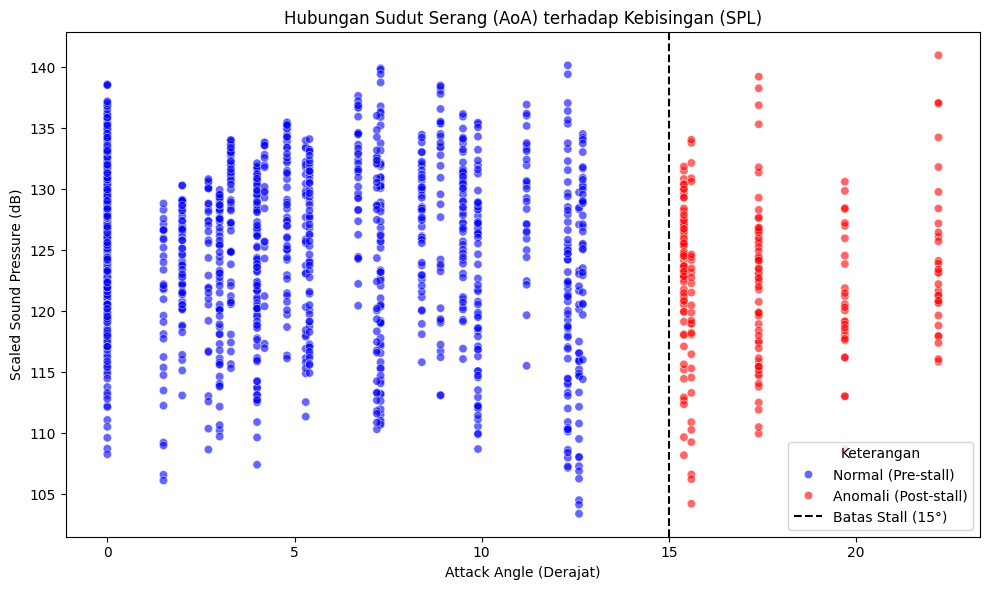

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# 1. Plot scatter dengan warna
ax = sns.scatterplot(
    data=S,
    x='attack-angle',
    y='scaled-sound-pressure',
    hue='is_stall',
    palette={0: 'blue', 1: 'red'}, # 0 = biru, 1 = merah
    alpha=0.6
)

# 2. Tambahkan garis batas stall
ax.axvline(x=15, color='black', linestyle='--', label='Batas Stall (15°)')

plt.title('Hubungan Sudut Serang (AoA) terhadap Kebisingan (SPL)')
plt.xlabel('Attack Angle (Derajat)')
plt.ylabel('Scaled Sound Pressure (dB)')


handles, labels = ax.get_legend_handles_labels()
new_labels = ['Normal (Pre-stall)', 'Anomali (Post-stall)', 'Batas Stall (15°)']
ax.legend(handles=handles, labels=new_labels, title='Keterangan', loc='lower right')

plt.tight_layout()
plt.show()

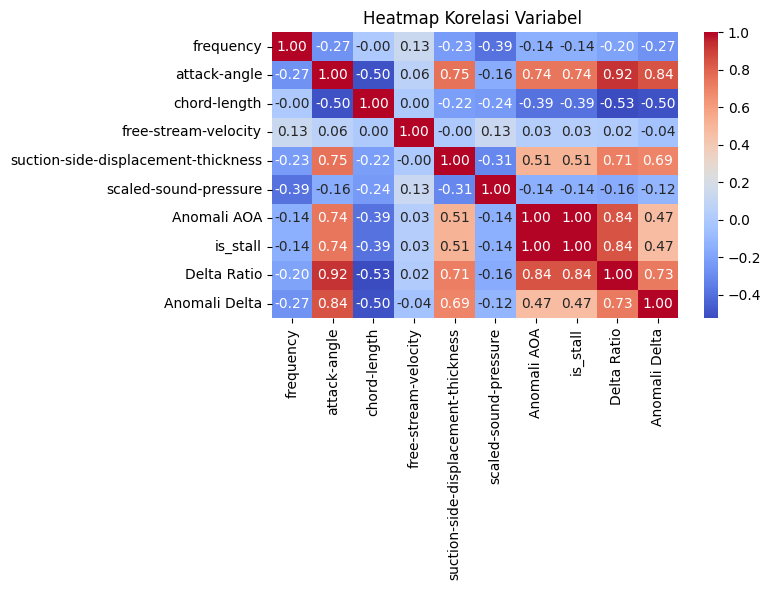

In [108]:
#Heatmap korelasi variabel numerik
plt.figure(figsize=(8, 6))
sns.heatmap(
    S.corr(numeric_only = True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Heatmap Korelasi Variabel ")
plt.tight_layout()
plt.show()

Di atas juga terlihat bahwasanya Delta Ratio memiliki korelasi yang sangat kuat terhadap AOA. Sehingga apabila kita memasukkan secara sembarangan terhadap model, maka akan terjadi multikolinearitas Sempurna.

Lebih lanjut, heatmap menunjukkan korelasi linear sederhana antara Attack Angle dan SPL hanya sebesar -0.16. Hal ini membuktikan bahwa hubungan antara aerodinamika dan kebisingan tidak bersifat linear murni, melainkan sangat bergantung pada interaksi dengan frekuensi. Oleh karena itu, pemodelan regresi berganda (yang mengontrol variabel lain seperti frequency) sangat krusial di sini.

In [109]:
import statsmodels.api as sm

S['log_delta'] = np.log(S['Delta Ratio'])
S['is_stall'] = (S['Anomali AOA'])
#Definisikan X dengan Dummy AoA + Log Delta (Tanpa AoA kontinu)

X_final = S[['frequency',
              'chord-length',
              'free-stream-velocity','log_delta',
              'is_stall']] # <--- Ini dummy-nya

X_final = sm.add_constant(X_final)
y = S['scaled-sound-pressure']

#Fit OLS
model_final = sm.OLS(y, X_final).fit()
print(model_final.summary())

                              OLS Regression Results                             
Dep. Variable:     scaled-sound-pressure   R-squared:                       0.498
Model:                               OLS   Adj. R-squared:                  0.496
Method:                    Least Squares   F-statistic:                     296.8
Date:                   Fri, 13 Nov 2026   Prob (F-statistic):          7.01e-221
Time:                           07:09:29   Log-Likelihood:                -4517.4
No. Observations:                   1503   AIC:                             9047.
Df Residuals:                       1497   BIC:                             9079.
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
co

Lebih lanjut akan kita uji multikolinearitas terkait model tersebut menggunakan Variance Inflation Factor

In [110]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Ambil variabel prediktor saja (tanpa target)
X_vif = S[['frequency', 'chord-length', 'free-stream-velocity', 'log_delta', 'is_stall']]
X_vif = sm.add_constant(X_vif)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print(vif_data)

                feature       VIF
0                 const  1.000000
1             frequency  1.150346
2          chord-length  1.644432
3  free-stream-velocity  1.022268
4             log_delta  2.613590
5              is_stall  1.796340


Dari atas sini terlihat bahwasanya VIF tergolong cukup kecil dimana dibawah 5. Hal tersebut menunjukkan bahwa notes pada keluaran model regresi tersebut terkait multikolinearitas tidak terbukti. Terdapat kemungkinan bahwa OLS mengeluarkan statement tersebut dikarenakan jumlahan variabel di tiap observasi bisa sangat berbeda. Seperti pada variabel frequency mencapai 20000 sedangkan Attack-On-Angle hanya sampai 22,7

Alhasil, penanganan yang tepat untuk menurunkan jumlahan condition number yang besar tersebut adalah lakukan standarisasi untuk seluruh variabel.

In [111]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

#Definisikan colom yang akan di standarisasi
cols_to_scale = ['frequency', 'chord-length', 'free-stream-velocity', 'log_delta']
S_scaled = S.copy()
S_scaled[cols_to_scale] = scaler.fit_transform(S[cols_to_scale])

# Shuffle data
S_scaled = S_scaled.sample(frac=1, random_state=42).reset_index(drop=True)

X_Std = S_scaled[['free-stream-velocity', 'frequency','log_delta', 'chord-length', 'is_stall']]
X_Std = sm.add_constant(X_Std)
Y_Std = S_scaled['scaled-sound-pressure']

model_std = sm.OLS(Y_Std, X_Std).fit()
print(model_std.summary())

                              OLS Regression Results                             
Dep. Variable:     scaled-sound-pressure   R-squared:                       0.498
Model:                               OLS   Adj. R-squared:                  0.496
Method:                    Least Squares   F-statistic:                     296.8
Date:                   Fri, 13 Nov 2026   Prob (F-statistic):          7.01e-221
Time:                           07:09:29   Log-Likelihood:                -4517.4
No. Observations:                   1503   AIC:                             9047.
Df Residuals:                       1497   BIC:                             9079.
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
co

Alhasil didapatkan model regresi secara matematisnya adalah

In [112]:
# Ambil koefisien dari model
params = model_std.params

# Print persamaan secara dinamis
print("Persamaan Regresi Akhir:")
print(f"Y = {params['const']:.2f} "
      f"+ ({params['frequency']:.2f} * frequency) "
      f"+ ({params['chord-length']:.2f} * chord_length) "
      f"+ ({params['free-stream-velocity']:.2f} * velocity) "
      f"+ ({params['log_delta']:.2f} * log_delta) "
      f"+ ({params['is_stall']:.2f} * is_stall)")

Persamaan Regresi Akhir:
Y = 125.03 + (-4.10 * frequency) + (-4.42 * chord_length) + (1.44 * velocity) + (-4.29 * log_delta) + (-1.35 * is_stall)


Selanjutnya akan kita cek terlebih dahulu perbandingan nilai aktual dan nilai yang telah kita buat modelnya

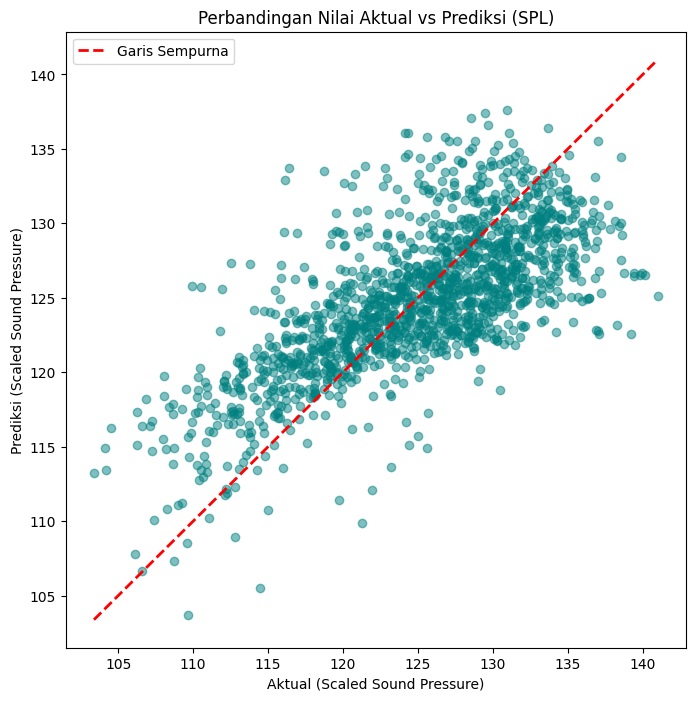

In [113]:
# Dapatkan nilai prediksi
y_pred = model_std.predict(X_Std)

plt.figure(figsize=(8, 8))
plt.scatter(Y_Std, y_pred, alpha=0.5, color='teal')
# ... sisa kode di bawahnya sama
# Gambar garis diagonal sempurna (y = x)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Garis Sempurna')

plt.title('Perbandingan Nilai Aktual vs Prediksi (SPL)')
plt.xlabel('Aktual (Scaled Sound Pressure)')
plt.ylabel('Prediksi (Scaled Sound Pressure)')
plt.legend()
plt.show()

Model regresi linear berganda yang dibangun menghasilkan R-squared sebesar 49.8%. Melalui plot perbandingan aktual vs prediksi, terlihat bahwa model mampu menangkap tren umum data (titik-titik mengikuti arah garis diagonal).

Namun, terdapat fenomena regression to the mean di mana model cenderung memprediksi nilai di sekitar rata-rata dan kesulitan menangkap nilai ekstrem (under-prediction pada nilai aktual tinggi). Hal ini sangat wajar mengingat kompleksitas aeroakustik yang bersifat non-linear (seperti hukum pangkat kecepatan
U^5).

Untuk penelitian lanjutan, penggunaan model non-linear seperti Polynomial Regression, Random Forest, atau XGBoost sangat disarankan untuk menangkap interaksi variabel yang lebih kompleks dan menekan error pada nilai ekstrem